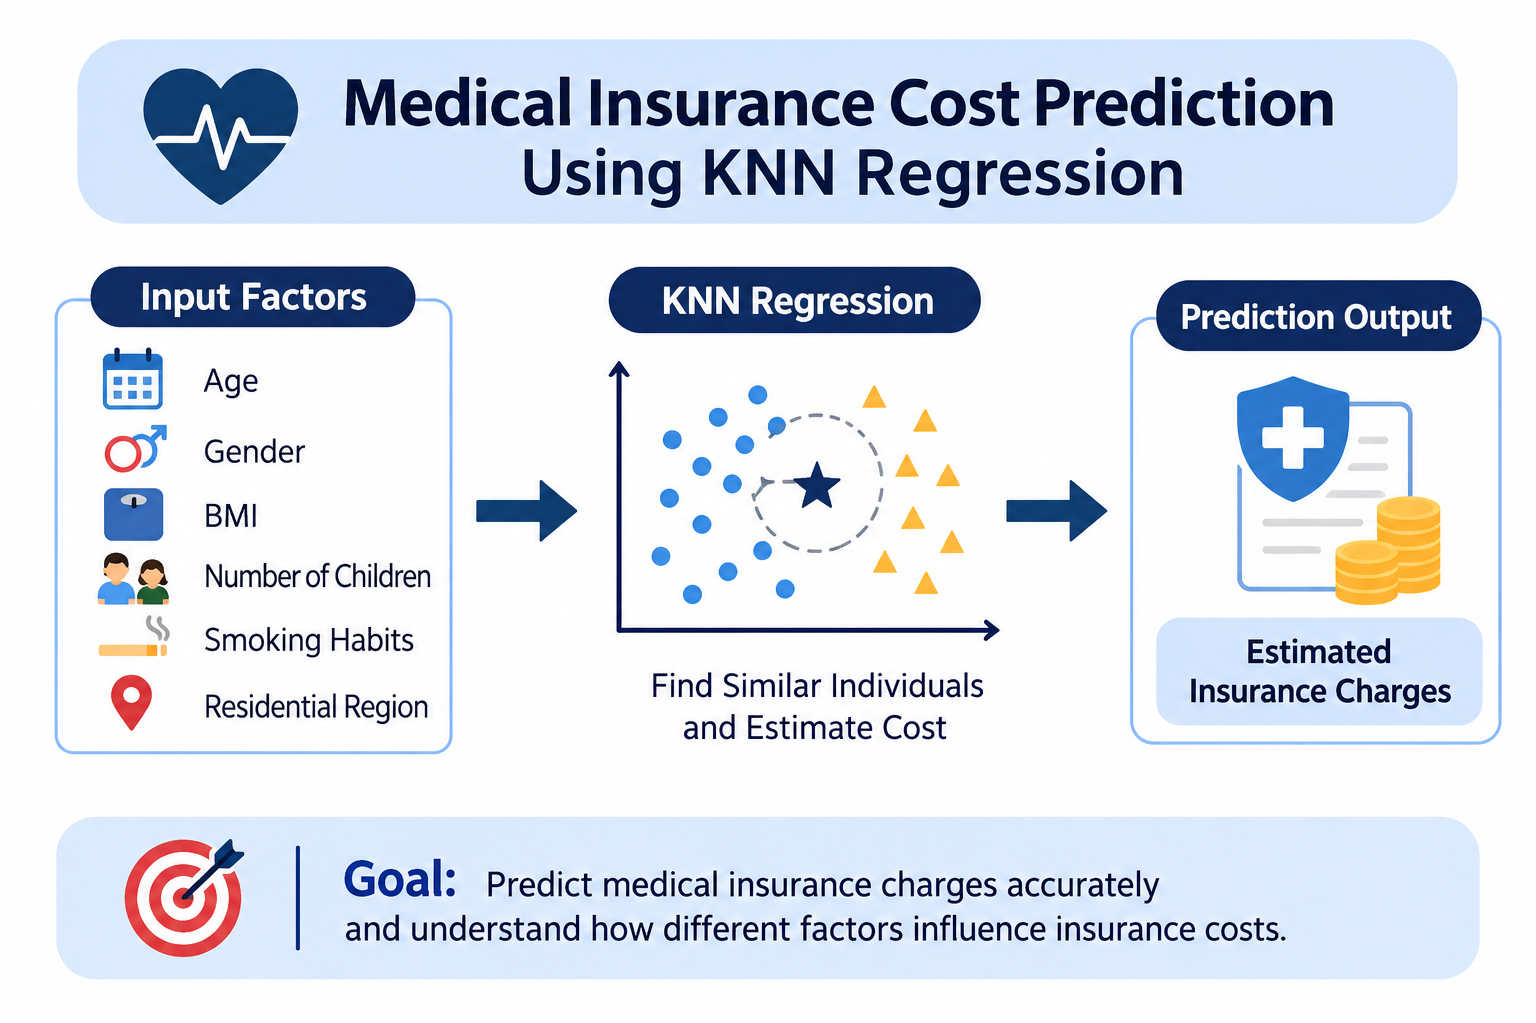

## Problem Definition

Medical Insurance Cost Prediction Using KNN Regression

Medical insurance costs vary from person to person depending on factors such as age, gender, BMI, number of children, smoking habits, and residential region.

The objective of this project is to develop a Machine Learning model using K-Nearest Neighbors (KNN) Regression to predict an individual's medical insurance charges based on these personal and lifestyle factors.

The model uses historical insurance data to identify similar individuals and estimate insurance costs for new customers.

##### Goal: 
To predict medical insurance charges accurately and understand how different factors influence insurance costs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

In [23]:
df = pd.read_csv("insurance.csv")

In [24]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [25]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [26]:
df.duplicated().sum()

np.int64(1)

In [27]:
df.drop_duplicates(inplace = True)

C:\Users\72IN\AppData\Local\Temp\ipykernel_23668\3424306917.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace = True)


In [28]:
df.duplicated().sum()

np.int64(0)

In [29]:
df.shape

(1337, 7)

In [30]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [31]:
X = df.drop("charges",axis = 1)
y = df["charges"]

In [32]:
X.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [33]:
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [34]:
X = pd.get_dummies(
    X, 
    columns = ['sex', 'smoker', 'region'], 
    dtype=int)

In [35]:
X.head()

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,1,0,0,1,0,0,0,1
1,18,33.770,1,0,1,1,0,0,0,1,0
2,28,33.000,3,0,1,1,0,0,0,1,0
3,33,22.705,0,0,1,1,0,0,1,0,0
4,32,28.880,0,0,1,1,0,0,1,0,0


In [36]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)
    

In [37]:
print("X train:",X_train.shape)
print("X test:",X_test.shape)
print("Y train:",y_train.shape)
print("Y test:",y_test.shape)

X train: (1069, 11)
X test: (268, 11)
Y train: (1069,)
Y test: (268,)


In [38]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [85]:
knn = KNeighborsRegressor(n_neighbors = 5)
knn

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None


In [86]:
knn.fit(X_train_scaled,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [87]:
y_pred = knn.predict(X_test_scaled)
print(y_pred[:10])

[ 9943.63101   7790.933946 16508.519848 31697.395948  5320.40298
  8206.77064  42540.630136  2266.262     8280.88476   9665.52866 ]


In [88]:
comparision = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})
print(comparision[:10])

        Actual     Predicted
0   8688.85885   9943.631010
1   5708.86700   7790.933946
2  11436.73815  16508.519848
3  38746.35510  31697.395948
4   4463.20510   5320.402980
5   9304.70190   8206.770640
6  38511.62830  42540.630136
7   2150.46900   2266.262000
8   7345.72660   8280.884760
9  10264.44210   9665.528660


In [89]:
new_data = pd.DataFrame({
    'age': [29],
    'sex': ['female'],
    'bmi': [26.5],
    'children': [1],
    'smoker': ['no'],
    'region': ['southeast']
})

In [90]:
new_data = pd.get_dummies(
    new_data,
    columns = ['sex', 'smoker', 'region'], 
    dtype=int)
    

In [91]:
new_data = new_data.reindex(
    columns = X_train.columns,
    fill_value = 0
)
print(new_data)

   age   bmi  children  sex_female  sex_male  smoker_no  smoker_yes  \
0   29  26.5         1           1         0          1           0   

   region_northeast  region_northwest  region_southeast  region_southwest  
0                 0                 0                 1                 0  


In [92]:
new_data_scaled = scaler.transform(new_data)
print(new_data_scaled)

[[-0.72886531 -0.66794823 -0.07050192  1.029432   -1.029432    0.50029231
  -0.50029231 -0.55682046 -0.57266946  1.65067825 -0.57410974]]


In [93]:
predicted_price = knn.predict(new_data_scaled)
print(predicted_price[0])

6786.758142000001


In [94]:
from sklearn.metrics import mean_absolute_error

In [95]:
mae = mean_absolute_error(
    y_test,
    y_pred
)
print("MAE:", mae)

MAE: 3494.6629988843283


In [96]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(
    y_test,
    y_pred,
)
print("MSE:",mse)

MSE: 30343819.725339793


In [97]:
from sklearn.metrics import root_mean_squared_error

rmse = root_mean_squared_error(
    y_test,
    y_pred,
)
print("RMSE:",rmse)

RMSE: 5508.522462996751


In [98]:
from sklearn.metrics import r2_score

r2 = r2_score(
    y_test,
    y_pred
    
)
print("R2 Score:",r2)

R2 Score: 0.8348690157046844
